## Auto Price Prediction

## Objective
.The goal of this project is to develop a machine learning model that can predict the price of an automobile based on its technical specifications and risk indicators.

## Loading Data

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [3]:
auto= pd.read_csv("auto_imports.csv")

In [4]:
auto

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [5]:
columns = ['symboling','normalized-losses','make','fuel-type','aspiration','num-of-doors','body-style','drive-wheels','engine-location','wheel-base','length','width','height','curb-weight','engine-type','num-of-cylinders','engine-size','fuel-system','bore','stroke','compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','price']

In [6]:
#adding the column names to dataset
auto.columns =columns 

In [7]:
auto

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [8]:
auto.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

## Basic Checks

In [27]:
auto.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,161,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,161,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,161,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


In [28]:
auto.tail()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470
199,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


In [29]:
auto.shape

(200, 26)

In [30]:
auto.describe()

,symboling,wheel-base,length,width,height,curb-weight,engine-size,compression-ratio,city-mpg,highway-mpg,price
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.830000,98.848000,174.228000,65.898000,53.791500,2555.705000,126.860000,10.170100,25.200000,30.705000,13205.690000
std,1.248557,6.038261,12.347132,2.102904,2.428449,518.594552,41.650501,4.014163,6.432487,6.827227,7966.982558
min,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,7.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.500000,166.675000,64.175000,52.000000,2163.000000,97.750000,8.575000,19.000000,25.000000,7775.000000
50%,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,119.500000,9.000000,24.000000,30.000000,10270.000000
75%,2.000000,102.400000,183.500000,66.675000,55.525000,2928.250000,142.000000,9.400000,30.000000,34.000000,16500.750000
max,3.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,23.000000,49.000000,54.000000,45400.000000


In [31]:
auto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          200 non-null    int64  
 1   normalized-losses  200 non-null    object 
 2   make               200 non-null    object 
 3   fuel-type          200 non-null    object 
 4   aspiration         200 non-null    object 
 5   num-of-doors       200 non-null    object 
 6   body-style         200 non-null    object 
 7   drive-wheels       200 non-null    object 
 8   engine-location    200 non-null    object 
 9   wheel-base         200 non-null    float64
 10  length             200 non-null    float64
 11  width              200 non-null    float64
 12  height             200 non-null    float64
 13  curb-weight        200 non-null    int64  
 14  engine-type        200 non-null    object 
 15  num-of-cylinders   200 non-null    object 
 16  engine-size        200 non

In [32]:
auto.describe(include='O')

,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system,bore,stroke,horsepower,peak-rpm
count,200,200,200,200,200,200,200,200,200,200,200,200,200,200,200
unique,51,22,2,2,2,5,3,2,6,7,8,38,36,58,22
top,161,toyota,gas,std,four,sedan,fwd,front,ohc,four,mpfi,3.62,3.40,68,4800
freq,47,32,180,164,115,94,118,197,145,156,91,27,23,21,38


In [33]:
auto.sample()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
63,-1,93,mercedes-benz,diesel,turbo,four,sedan,rwd,front,110.0,...,183,idi,3.58,3.64,21.5,123,4350,22,25,25552


In [34]:
auto.columns

Index(['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type',
       'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'price'],
      dtype='object')

In [35]:
auto.duplicated().sum()

0

## EDA

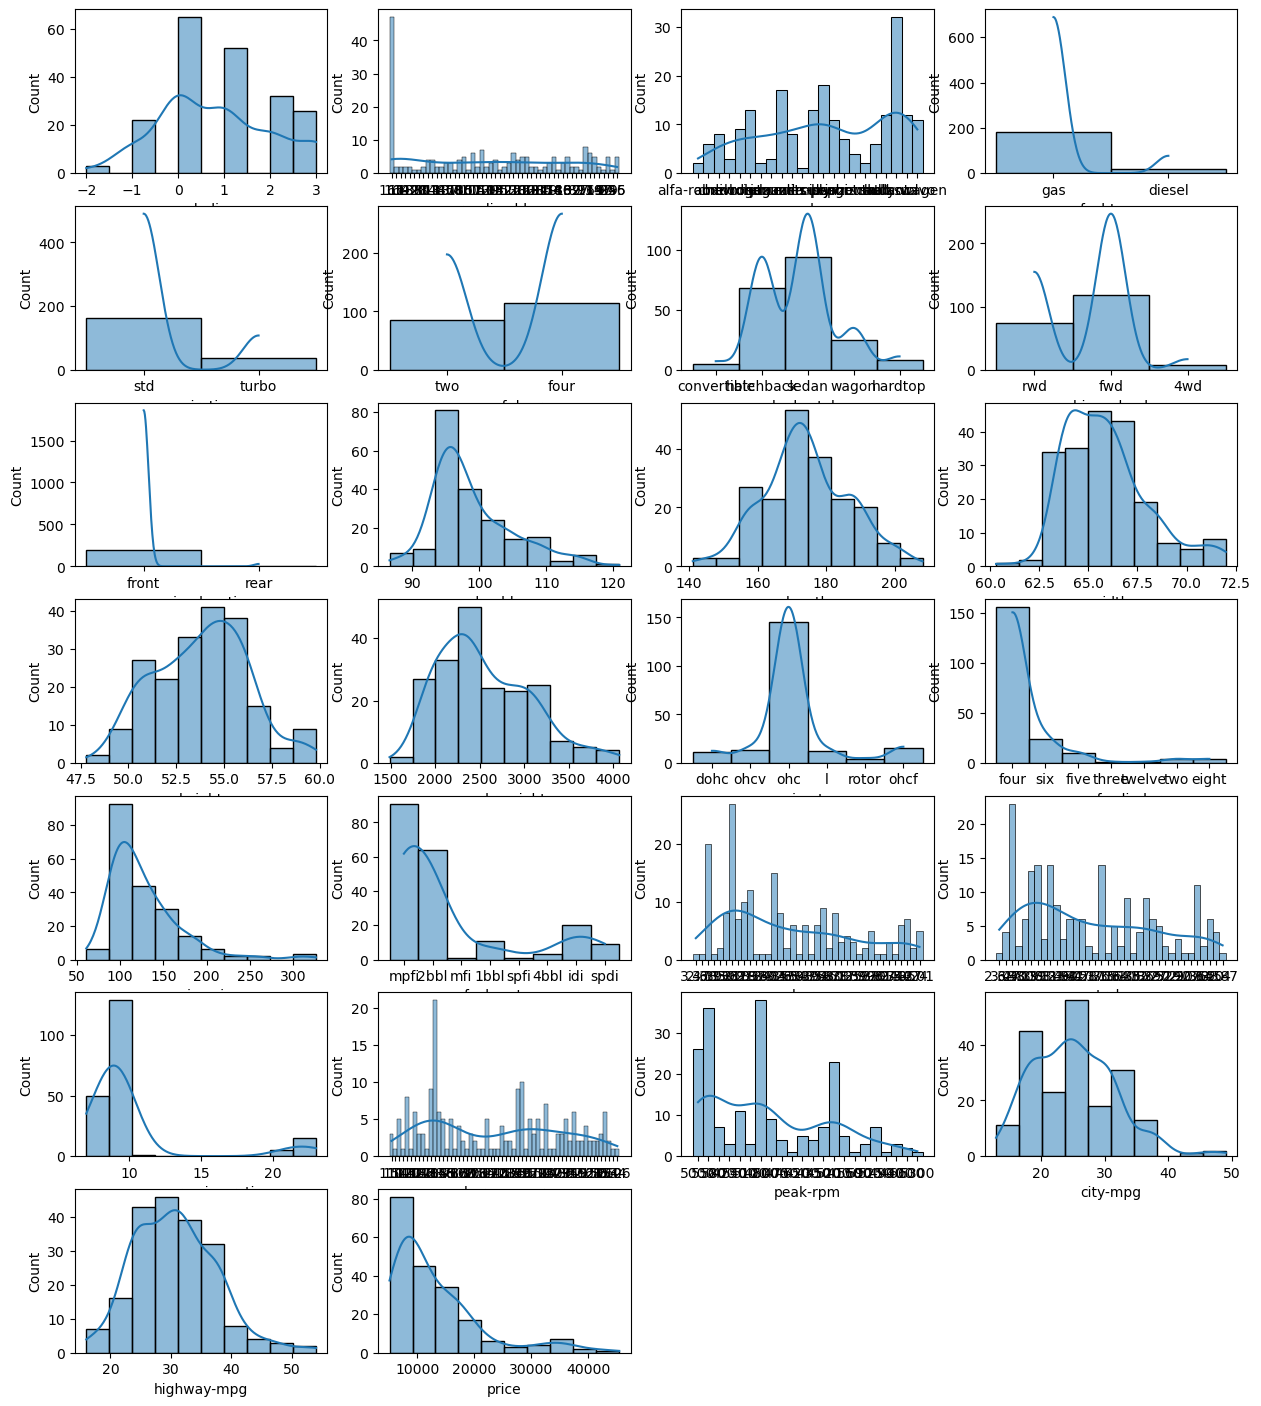

In [39]:
plt.figure(figsize=(15,20))
pos=1
for i in auto.columns:
    plt.subplot(8,4,pos)
    sns.histplot(auto[i],bins=10,kde=True)
    pos=pos+1

In [ ]:
By checking the histograms, some columns show unusual peaks or extreme values:
>horsepower, engine-size, curb-weight, price
Implication:
Apply outlier handling (IQR or winsorization) before training models.

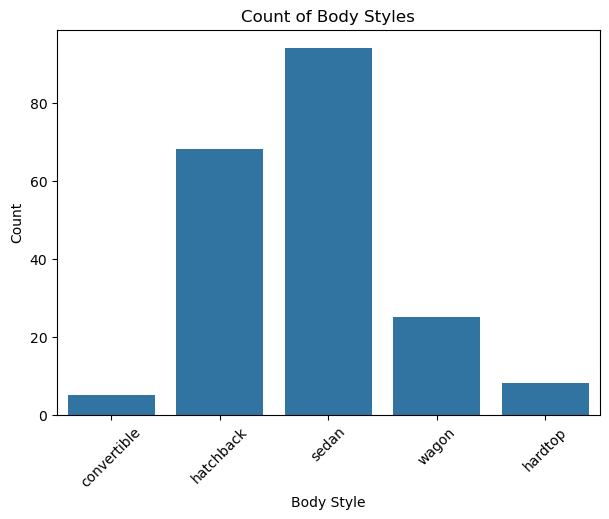

In [42]:
plt.figure(figsize=(7,5))
sns.countplot(data=auto, x='body-style')
plt.title("Count of Body Styles")
plt.xlabel("Body Style")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()
#Body-style distribution shows clear dominance of sedans and hatchbacks, while convertibles and hardtops are very rare.

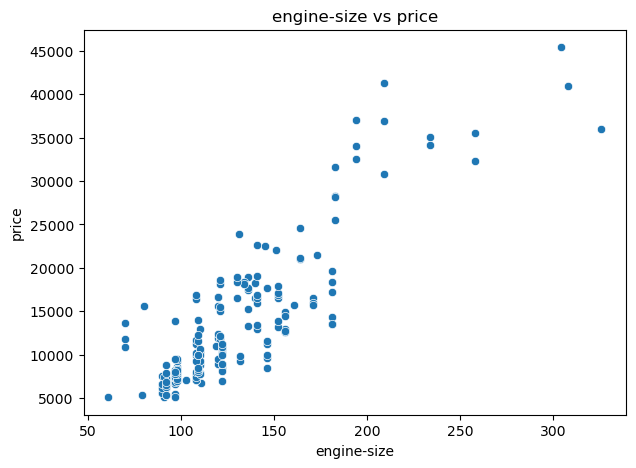

In [44]:
col1 = 'engine-size'
col2 = 'price'

plt.figure(figsize=(7,5))
sns.scatterplot(data=auto, x=col1, y=col2)
plt.title(f"{col1} vs {col2}")
plt.show()
#The scatter plot between engine-size and price shows a strong positive relationship, where larger engines generally correspond to higher vehicle prices. 
#The trend is moderately non-linear with a noticeable increase for high engine-size vehicles.

## Data Preprocessing and Feature Engineering

In [11]:
# Hnadle the ? sign and replace with nan values and then impute with mean and mode
auto['num-of-doors'].value_counts()

num-of-doors
four    113
two      85
?         2
Name: count, dtype: int64

In [12]:
auto['bore'].value_counts()

bore
3.62    23
3.19    20
3.15    15
2.97    12
3.03    10
3.46     9
3.31     8
3.78     8
3.43     8
3.27     7
2.91     7
3.39     6
3.54     6
3.05     6
3.58     6
3.70     5
3.01     5
3.35     4
?        4
3.17     3
3.59     3
3.74     3
3.24     2
3.63     2
3.50     2
3.80     2
3.33     2
3.08     1
3.94     1
3.13     1
2.54     1
2.99     1
3.61     1
3.34     1
3.60     1
2.92     1
3.76     1
2.68     1
3.47     1
Name: count, dtype: int64

In [13]:
auto['stroke'].value_counts()

stroke
3.40    19
3.23    14
3.15    14
3.03    14
3.39    13
2.64    11
3.29     9
3.35     9
3.46     8
3.27     6
3.19     6
3.41     6
3.07     6
3.58     6
3.50     6
3.64     5
3.52     5
3.86     4
3.54     4
3.47     4
?        4
3.90     3
3.11     3
2.90     3
3.10     2
4.17     2
2.80     2
2.19     2
3.08     2
2.36     1
2.68     1
3.16     1
2.07     1
3.21     1
3.12     1
2.76     1
2.87     1
Name: count, dtype: int64

In [14]:
auto['horsepower'].value_counts()


horsepower
68     19
69     10
116     9
70      9
110     8
95      7
114     6
101     6
62      6
88      6
145     5
82      5
76      5
97      5
160     5
102     5
84      5
123     4
86      4
92      4
207     3
73      3
111     3
90      3
152     3
85      3
182     3
121     3
56      2
112     2
94      2
156     2
?       2
52      2
162     2
161     2
155     2
176     2
184     2
100     2
55      1
134     1
115     1
140     1
48      1
58      1
60      1
78      1
262     1
200     1
135     1
64      1
120     1
72      1
154     1
143     1
142     1
175     1
106     1
Name: count, dtype: int64

In [15]:
auto['peak-rpm'].value_counts()


peak-rpm
5500    36
4800    36
5000    26
5200    23
5400    11
6000     9
5800     7
5250     7
4500     7
4150     5
4200     5
4350     4
4750     4
5100     3
5900     3
4250     3
4400     3
?        2
6600     2
4650     1
5600     1
4900     1
5300     1
Name: count, dtype: int64

In [16]:
auto['price'].value_counts()


price
16500    2
7775     2
7295     2
7957     2
6229     2
        ..
16503    1
5389     1
6189     1
6669     1
22625    1
Name: count, Length: 185, dtype: int64

In [17]:
auto.replace('?',np.nan, inplace =True)

In [18]:
auto

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,NaN,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [20]:
# we have got null values in columns normalized losses,bore,body-style,stroke,horsepower,peak-rpm
auto.isnull().sum()

symboling             0
normalized-losses    36
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [21]:
col=auto.columns

In [22]:
col

Index(['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type',
       'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'price'],
      dtype='object')

In [23]:
for col_name in col:
    if auto[col_name].dtypes=='object':
        auto[col_name] = auto[col_name].fillna(auto[col_name].mode()[0])
    else:
        auto[col_name]=auto[col_name].fillna(auto[col_name].median()) #handling the mising values

In [24]:
auto.isnull().sum() 

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

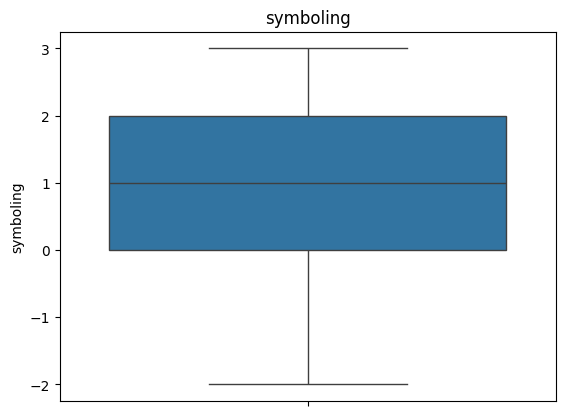

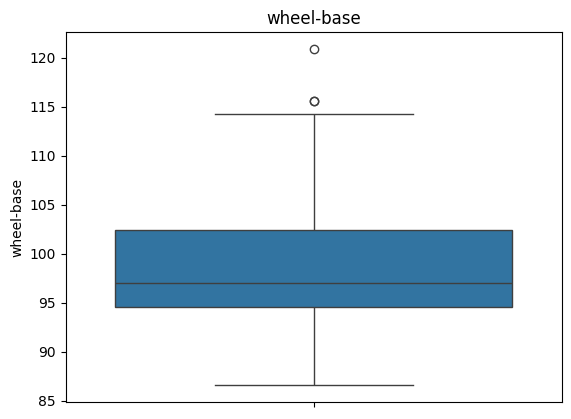

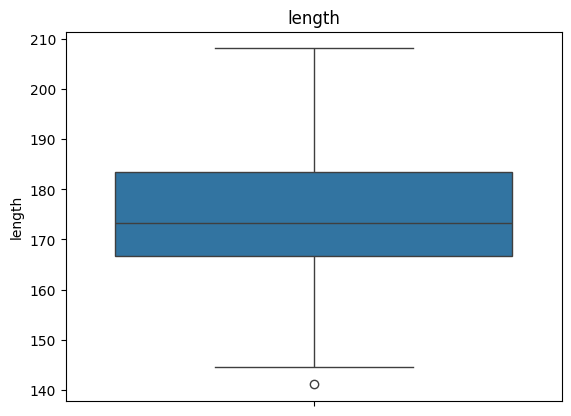

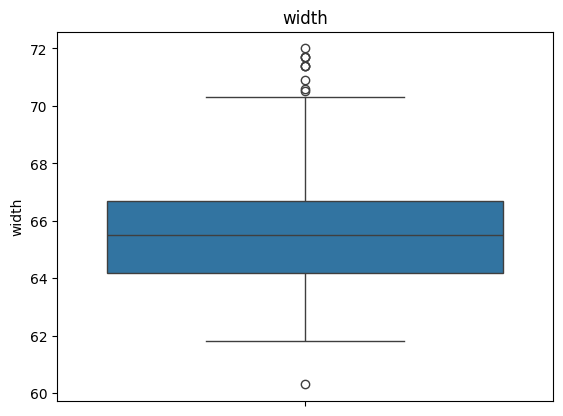

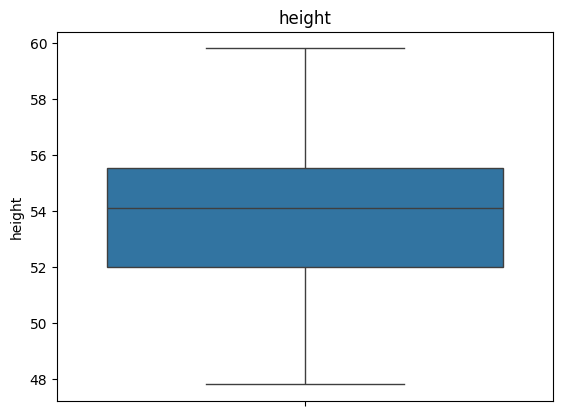

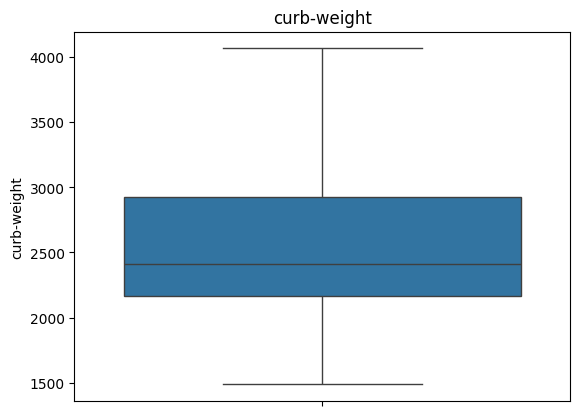

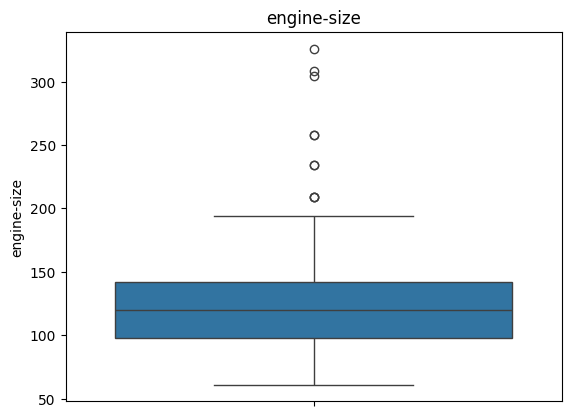

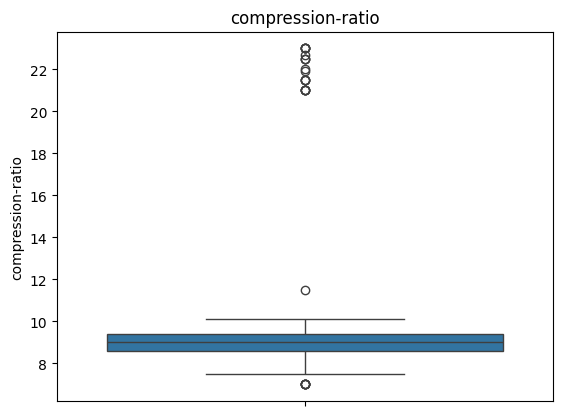

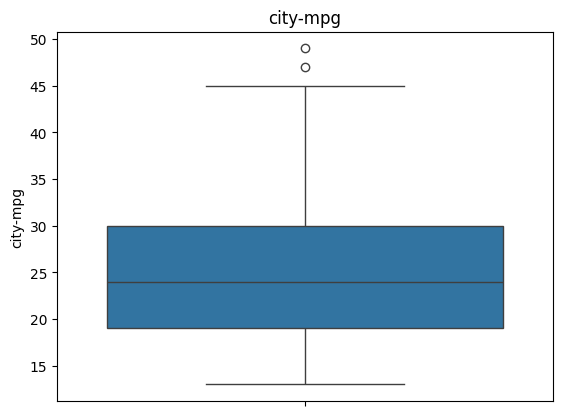

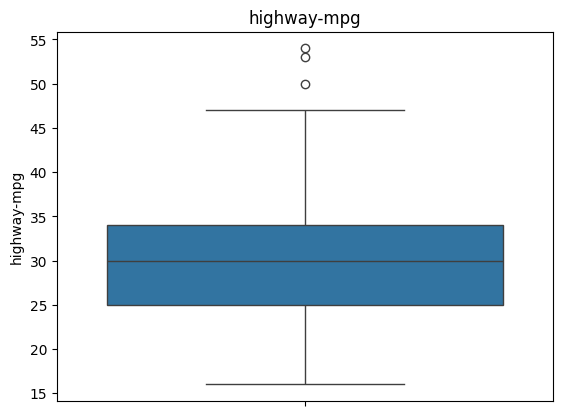

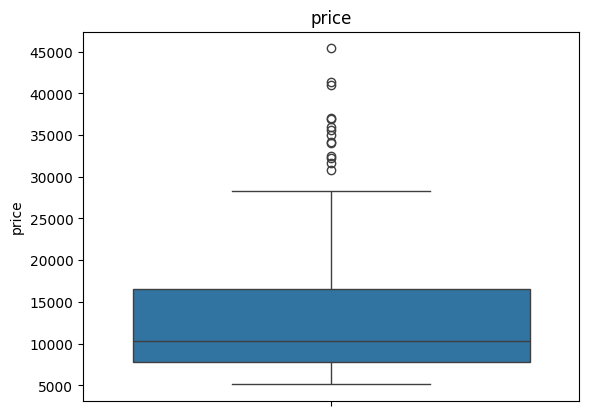

In [ ]:
#Checking for outliers and handling it
for col_name in col1:
    sns.boxplot(auto[col_name])
    plt.title(col_name)
    plt.show()

In [ ]:
def remove_outliers_iqr(df):
    df_clean = df.copy()
    numeric_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns

    for col in numeric_cols:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]

    print("Outlier removal complete!")
    print(f"Rows before: {df.shape[0]} → after: {df_clean.shape[0]}")
    return df_clean

In [ ]:
auto_cleaned = remove_outliers_iqr(auto)

✅ Outlier removal complete!
Rows before: 200 → after: 147


In [ ]:
print("Boxplots after removing outliers:")


📊 Boxplots after removing outliers:


📊 Boxplots before removing outliers:


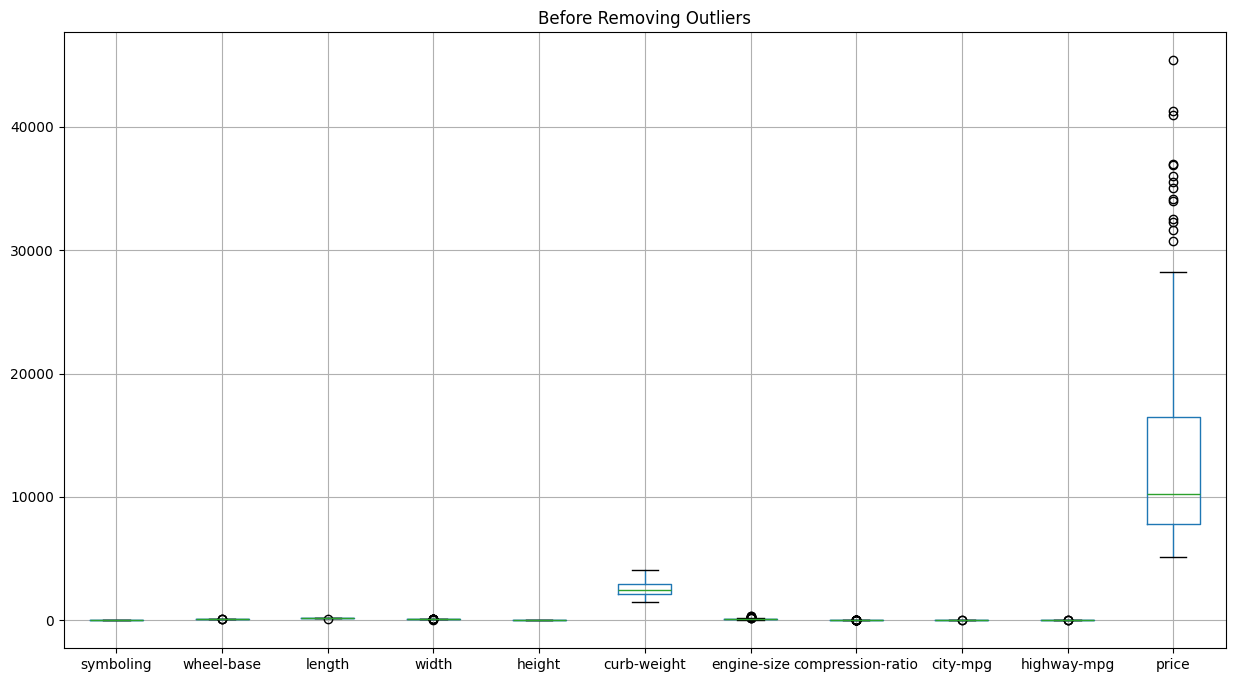

✅ Outlier removal complete!
Rows before: 200 → after: 147

📊 Boxplots after removing outliers:


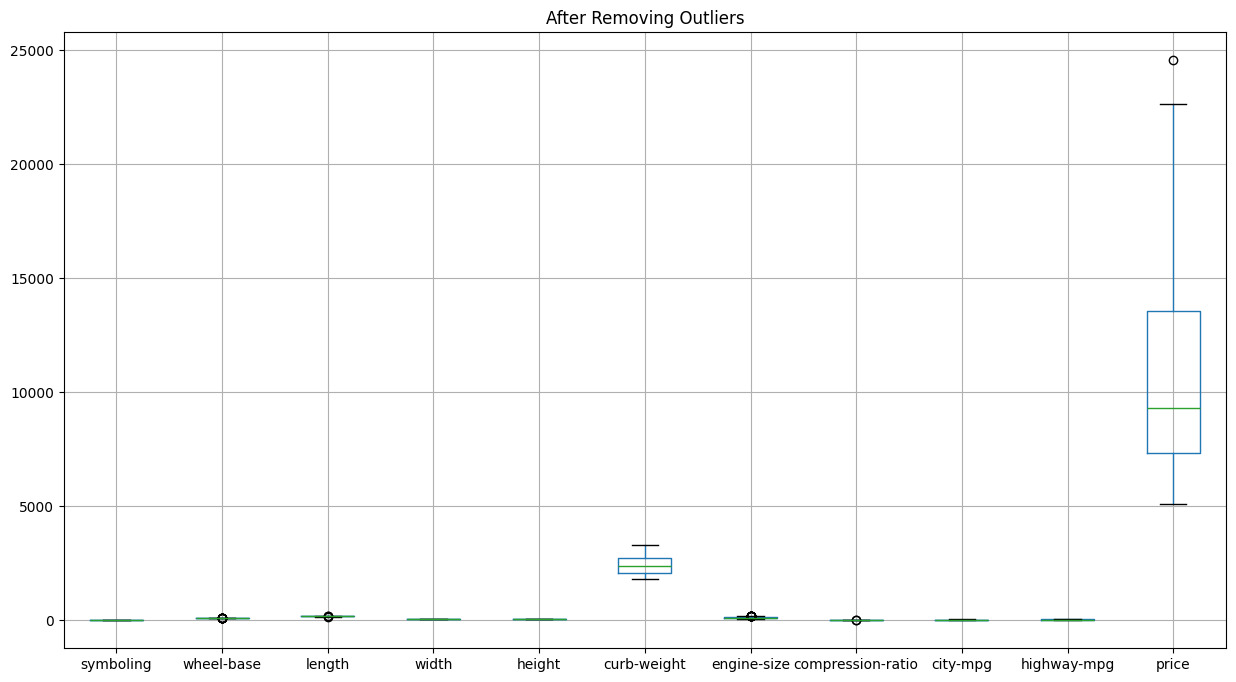

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


numeric_cols = auto.select_dtypes(include=['float64', 'int64']).columns


print("Boxplots before removing outliers:")

plt.figure(figsize=(15, 8))
auto[numeric_cols].boxplot()
plt.title("Before Removing Outliers")
plt.show()


def remove_outliers_iqr(df):
    df_clean = df.copy()
    numeric_cols_local = df_clean.select_dtypes(include=['float64', 'int64']).columns  

    for col in numeric_cols_local:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]

    print("Outlier removal complete!")
    print(f"Rows before: {df.shape[0]} → after: {df_clean.shape[0]}")
    return df_clean

auto_cleaned = remove_outliers_iqr(auto)


print("\nBoxplots after removing outliers:")

plt.figure(figsize=(15, 8))
auto_cleaned[numeric_cols].boxplot()
plt.title("After Removing Outliers")
plt.show()


In [ ]:
col2 = auto.select_dtypes(include='O').columns
col2

Index(['normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
       'body-style', 'drive-wheels', 'engine-location', 'engine-type',
       'num-of-cylinders', 'fuel-system', 'bore', 'stroke', 'horsepower',
       'peak-rpm'],
      dtype='object')

In [45]:
# Ordinal encode cylinders
cyl_map = {'two':2,'three':3,'four':4,'five':5,'six':6,'eight':8,'twelve':12}
auto['num-of-cylinders'] = auto['num-of-cylinders'].map(cyl_map)

# Target encode make
import category_encoders as ce
target_enc = ce.TargetEncoder(cols=['make'])
auto['make'] = target_enc.fit_transform(auto['make'], auto['price'])

# One-hot encode the rest
one_hot_cols = ['fuel-type','aspiration','num-of-doors','body-style',
                'drive-wheels','engine-location','engine-type','fuel-system']

auto = pd.get_dummies(auto, columns=one_hot_cols, drop_first=True)


In [46]:
from sklearn.preprocessing import MinMaxScaler 
mm=MinMaxScaler()
for i in auto.columns:
    auto[[i]]=mm.fit_transform(auto[[i]]) 
auto

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,1.0,0.502618,0.414483,0.058309,0.413433,0.324786,0.083333,0.411171,0.2,0.260377,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.6,0.502618,0.414483,0.230321,0.449254,0.444444,0.383333,0.517843,0.4,0.343396,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.8,0.518325,0.476714,0.384840,0.529851,0.504274,0.541667,0.329325,0.2,0.181132,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.8,0.518325,0.476714,0.373178,0.529851,0.521368,0.541667,0.518231,0.3,0.283019,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.8,0.502618,0.476714,0.384840,0.540299,0.512821,0.441667,0.395268,0.3,0.283019,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.2,0.157068,0.543105,0.655977,0.711940,0.735043,0.641667,0.567882,0.2,0.301887,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
196,0.2,0.157068,0.543105,0.655977,0.711940,0.726496,0.641667,0.605508,0.2,0.301887,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
197,0.2,0.157068,0.543105,0.655977,0.711940,0.735043,0.641667,0.591156,0.4,0.422642,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
198,0.2,0.157068,0.543105,0.655977,0.711940,0.735043,0.641667,0.670675,0.4,0.316981,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Feature Selection

In [47]:
res1=auto.corr()
res1

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
symboling,1.000000,0.452557,-0.134497,-0.529145,-0.364511,-0.237262,-0.542261,-0.234743,-0.115952,-0.112069,...,0.038868,-0.012865,0.248910,-0.026852,0.215014,-0.195381,0.123513,0.003789,0.184559,0.066595
normalized-losses,0.452557,1.000000,0.270647,0.051106,0.163820,0.207871,-0.335627,0.260506,0.256485,0.295718,...,-0.185529,0.188141,0.084831,-0.260386,0.073279,-0.066231,0.032063,0.279129,0.121392,0.064165
make,-0.134497,0.270647,1.000000,0.568617,0.608390,0.665195,0.251577,0.683232,0.534275,0.668108,...,-0.007012,0.252732,-0.045251,-0.373605,-0.039089,0.168084,-0.031829,0.370658,-0.090644,-0.004152
wheel-base,-0.529145,0.051106,0.568617,1.000000,0.879005,0.814593,0.583789,0.787584,0.348622,0.576779,...,-0.189480,0.163908,-0.084152,-0.401245,-0.072692,0.306706,-0.034696,0.359298,-0.121862,-0.033519
length,-0.364511,0.163820,0.608390,0.879005,1.000000,0.857271,0.492955,0.881058,0.439936,0.685531,...,-0.123952,0.243285,-0.060640,-0.478216,-0.052382,0.210616,-0.005917,0.510386,-0.083918,-0.009370
width,-0.237262,0.207871,0.665195,0.814593,0.857271,1.000000,0.300995,0.867720,0.519752,0.731100,...,-0.127330,0.361868,-0.013485,-0.520552,-0.011648,0.243448,0.013585,0.456085,-0.046936,-0.023588
height,-0.542261,-0.335627,0.251577,0.583789,0.492955,0.300995,1.000000,0.310660,0.004327,0.076255,...,-0.055424,-0.073592,-0.247190,-0.085648,-0.213529,0.281198,-0.105101,0.127971,-0.289978,-0.069985
curb-weight,-0.234743,0.260506,0.683232,0.787584,0.881058,0.867720,0.310660,1.000000,0.604608,0.849090,...,-0.081782,0.407790,-0.039893,-0.567621,-0.041518,0.221082,0.034985,0.510248,-0.002534,0.024433
num-of-cylinders,-0.115952,0.256485,0.534275,0.348622,0.439936,0.519752,0.004327,0.604608,1.000000,0.848031,...,0.009410,0.675111,-0.318992,-0.246527,-0.275553,-0.020457,-0.024429,0.386646,-0.074807,-0.024429
engine-size,-0.112069,0.295718,0.668108,0.576779,0.685531,0.731100,0.076255,0.849090,0.848031,1.000000,...,-0.016403,0.570101,-0.186917,-0.434471,-0.168889,0.070925,0.049720,0.476765,0.004795,-0.013411


In [48]:
res=auto[auto.columns[:-1]].corr() 
res

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi
symboling,1.000000,0.452557,-0.134497,-0.529145,-0.364511,-0.237262,-0.542261,-0.234743,-0.115952,-0.112069,...,-0.066085,0.038868,-0.012865,0.248910,-0.026852,0.215014,-0.195381,0.123513,0.003789,0.184559
normalized-losses,0.452557,1.000000,0.270647,0.051106,0.163820,0.207871,-0.335627,0.260506,0.256485,0.295718,...,-0.219610,-0.185529,0.188141,0.084831,-0.260386,0.073279,-0.066231,0.032063,0.279129,0.121392
make,-0.134497,0.270647,1.000000,0.568617,0.608390,0.665195,0.251577,0.683232,0.534275,0.668108,...,-0.183004,-0.007012,0.252732,-0.045251,-0.373605,-0.039089,0.168084,-0.031829,0.370658,-0.090644
wheel-base,-0.529145,0.051106,0.568617,1.000000,0.879005,0.814593,0.583789,0.787584,0.348622,0.576779,...,-0.219490,-0.189480,0.163908,-0.084152,-0.401245,-0.072692,0.306706,-0.034696,0.359298,-0.121862
length,-0.364511,0.163820,0.608390,0.879005,1.000000,0.857271,0.492955,0.881058,0.439936,0.685531,...,-0.276359,-0.123952,0.243285,-0.060640,-0.478216,-0.052382,0.210616,-0.005917,0.510386,-0.083918
width,-0.237262,0.207871,0.665195,0.814593,0.857271,1.000000,0.300995,0.867720,0.519752,0.731100,...,-0.278713,-0.127330,0.361868,-0.013485,-0.520552,-0.011648,0.243448,0.013585,0.456085,-0.046936
height,-0.542261,-0.335627,0.251577,0.583789,0.492955,0.300995,1.000000,0.310660,0.004327,0.076255,...,0.016792,-0.055424,-0.073592,-0.247190,-0.085648,-0.213529,0.281198,-0.105101,0.127971,-0.289978
curb-weight,-0.234743,0.260506,0.683232,0.787584,0.881058,0.867720,0.310660,1.000000,0.604608,0.849090,...,-0.409261,-0.081782,0.407790,-0.039893,-0.567621,-0.041518,0.221082,0.034985,0.510248,-0.002534
num-of-cylinders,-0.115952,0.256485,0.534275,0.348622,0.439936,0.519752,0.004327,0.604608,1.000000,0.848031,...,-0.305812,0.009410,0.675111,-0.318992,-0.246527,-0.275553,-0.020457,-0.024429,0.386646,-0.074807
engine-size,-0.112069,0.295718,0.668108,0.576779,0.685531,0.731100,0.076255,0.849090,0.848031,1.000000,...,-0.353000,-0.016403,0.570101,-0.186917,-0.434471,-0.168889,0.070925,0.049720,0.476765,0.004795


In [49]:
res[res>0.8]

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi
symboling,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
normalized-losses,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
make,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheel-base,NaN,NaN,NaN,1.000000,0.879005,0.814593,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
length,NaN,NaN,NaN,0.879005,1.000000,0.857271,NaN,0.881058,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
width,NaN,NaN,NaN,0.814593,0.857271,1.000000,NaN,0.867720,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
height,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
curb-weight,NaN,NaN,NaN,NaN,0.881058,0.867720,NaN,1.000000,NaN,0.849090,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num-of-cylinders,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.848031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine-size,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.849090,0.848031,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
auto.drop('city-mpg',axis=1,inplace=True)

In [53]:
res=auto[auto.columns[:-1]].corr() 
res

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi
symboling,1.000000,0.452557,-0.134497,-0.529145,-0.364511,-0.237262,-0.542261,-0.234743,-0.115952,-0.112069,...,-0.066085,0.038868,-0.012865,0.248910,-0.026852,0.215014,-0.195381,0.123513,0.003789,0.184559
normalized-losses,0.452557,1.000000,0.270647,0.051106,0.163820,0.207871,-0.335627,0.260506,0.256485,0.295718,...,-0.219610,-0.185529,0.188141,0.084831,-0.260386,0.073279,-0.066231,0.032063,0.279129,0.121392
make,-0.134497,0.270647,1.000000,0.568617,0.608390,0.665195,0.251577,0.683232,0.534275,0.668108,...,-0.183004,-0.007012,0.252732,-0.045251,-0.373605,-0.039089,0.168084,-0.031829,0.370658,-0.090644
wheel-base,-0.529145,0.051106,0.568617,1.000000,0.879005,0.814593,0.583789,0.787584,0.348622,0.576779,...,-0.219490,-0.189480,0.163908,-0.084152,-0.401245,-0.072692,0.306706,-0.034696,0.359298,-0.121862
length,-0.364511,0.163820,0.608390,0.879005,1.000000,0.857271,0.492955,0.881058,0.439936,0.685531,...,-0.276359,-0.123952,0.243285,-0.060640,-0.478216,-0.052382,0.210616,-0.005917,0.510386,-0.083918
width,-0.237262,0.207871,0.665195,0.814593,0.857271,1.000000,0.300995,0.867720,0.519752,0.731100,...,-0.278713,-0.127330,0.361868,-0.013485,-0.520552,-0.011648,0.243448,0.013585,0.456085,-0.046936
height,-0.542261,-0.335627,0.251577,0.583789,0.492955,0.300995,1.000000,0.310660,0.004327,0.076255,...,0.016792,-0.055424,-0.073592,-0.247190,-0.085648,-0.213529,0.281198,-0.105101,0.127971,-0.289978
curb-weight,-0.234743,0.260506,0.683232,0.787584,0.881058,0.867720,0.310660,1.000000,0.604608,0.849090,...,-0.409261,-0.081782,0.407790,-0.039893,-0.567621,-0.041518,0.221082,0.034985,0.510248,-0.002534
num-of-cylinders,-0.115952,0.256485,0.534275,0.348622,0.439936,0.519752,0.004327,0.604608,1.000000,0.848031,...,-0.305812,0.009410,0.675111,-0.318992,-0.246527,-0.275553,-0.020457,-0.024429,0.386646,-0.074807
engine-size,-0.112069,0.295718,0.668108,0.576779,0.685531,0.731100,0.076255,0.849090,0.848031,1.000000,...,-0.353000,-0.016403,0.570101,-0.186917,-0.434471,-0.168889,0.070925,0.049720,0.476765,0.004795


In [54]:
res[res>0.8]

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi
symboling,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
normalized-losses,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
make,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheel-base,NaN,NaN,NaN,1.000000,0.879005,0.814593,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
length,NaN,NaN,NaN,0.879005,1.000000,0.857271,NaN,0.881058,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
width,NaN,NaN,NaN,0.814593,0.857271,1.000000,NaN,0.867720,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
height,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
curb-weight,NaN,NaN,NaN,NaN,0.881058,0.867720,NaN,1.000000,NaN,0.849090,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num-of-cylinders,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.848031,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine-size,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.849090,0.848031,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Model Building

In [55]:
from sklearn.linear_model import LinearRegression 
from sklearn.model_selection import train_test_split

In [56]:
x=auto[auto.columns[:-1]]
y=auto['price']

In [57]:
x_train,x_test,y_train,y_test = train_test_split(x,y, train_size =0.75, random_state=42)

In [58]:
x_train

,symboling,normalized-losses,make,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,...,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi
114,0.6,0.282723,0.196167,0.206997,0.241791,0.299145,0.250000,0.166796,0.2,0.109434,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
173,1.0,0.691099,0.000000,0.475219,0.632836,0.632479,0.350000,0.577192,0.4,0.415094,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,0.6,0.486911,0.476714,0.559767,0.770149,0.948718,0.658333,0.525989,0.3,0.283019,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
126,0.8,0.502618,0.279996,0.276968,0.532836,0.538462,0.225000,0.377036,0.2,0.267925,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
117,0.6,0.465969,0.196167,0.206997,0.391045,0.299145,0.250000,0.194337,0.2,0.109434,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,0.4,0.502618,0.440944,0.804665,0.862687,0.692308,0.908333,0.753297,0.2,0.343396,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
14,0.4,0.502618,0.760732,0.492711,0.786567,0.649573,0.491667,0.733902,0.4,0.558491,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
92,0.6,0.298429,0.177869,0.230321,0.361194,0.299145,0.558333,0.187355,0.2,0.135849,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
179,0.8,0.151832,0.217160,0.311953,0.456716,0.444444,0.658333,0.301009,0.2,0.135849,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [60]:
l_model=LinearRegression()

In [61]:
l_model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [62]:
y_pred =l_model.predict(x_test)


array([9.51045132e-02, 7.88491137e-01, 6.97582047e-03, 7.29854526e-02,
       1.75065786e-01, 7.04781292e-02, 8.89777072e-01, 1.20897671e-01,
       2.70095824e-01, 7.66645152e-01, 6.57415223e-01, 1.08658954e-01,
       1.50960727e-01, 1.86460454e-01, 2.02993893e-01, 6.59599821e-02,
       8.38339705e-02, 5.16359664e-02, 7.62375254e-02, 7.43210367e-01,
       7.92165235e-01, 8.19224468e-04, 4.46849710e-02, 7.15207785e-02,
       5.72414478e-01, 1.52102676e-01, 1.03296758e-01, 7.21562981e-01,
       1.03693958e-01, 3.35186932e-01, 2.93108584e-01, 3.61700015e-02,
       9.25227149e-02, 6.38250335e-02, 9.08594409e-02, 2.00635520e-01,
       6.16900849e-02, 6.59599821e-02, 1.20922496e-01, 1.20177747e-01,
       2.42068418e-01, 4.06310511e-01, 1.28518941e-01, 6.18390348e-02,
       6.80452808e-01, 2.91122586e-01, 4.31209970e-02, 1.12705427e-02,
       7.18683283e-02, 4.91782930e-02])

## Model Evaluation

In [63]:
from sklearn.metrics import *

In [64]:
r2_on_test = r2_score(y_test,y_pred) #how far the model have learnt--> r2_score
r2_on_test

1.0

## Testing with other Algorithms

## Decision Tree

In [66]:
from sklearn.tree import *
model = DecisionTreeRegressor(random_state=24, criterion='squared_error', splitter='best', max_depth=None)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

In [67]:
import math 
r2 = r2_score(y_test, y_pred)
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=math.sqrt(mean_squared_error(y_test,y_pred))
print(mse,mae,rmse)
print(f"Model Accuracy: {r2*100:.2f}%")

0.001555593613162844 0.0167052281416017 0.03944101435261071
Model Accuracy: 97.56%


## Random Forest

In [81]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score

param_grid = {
    'n_estimators': [100, 200, 400, 600],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 6],
    'max_features': ['auto', 'sqrt', 0.6, 0.8],
    'bootstrap': [True, False]
}

rf = RandomForestRegressor(random_state=42)

grid = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    scoring='r2',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV R² Score:", round(grid.best_score_, 4))
y_pred = grid.predict(x_test)
print("Test R² Score:", round(r2_score(y_test, y_pred), 4))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 15, 'bootstrap': False}
Best CV R² Score: 0.9816
Test R² Score: 0.9873


## XGBOOST 

In [88]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score
param_grid = {
    'n_estimators': [200, 400, 600],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 1, 5],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 2, 5]
}
xgb = XGBRegressor(random_state=42)

grid = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=30,         
    scoring='r2',
    cv=5,
    verbose=1,
    n_jobs=-1
)
grid.fit(x_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best R² Score:", round(grid.best_score_, 4))
y_pred = grid.predict(x_test)
print("Test R²:", round(r2_score(y_test, y_pred), 4))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 0.8}
Best R² Score: 0.9746
Test R²: 0.9939


## Gradient Boosting

In [84]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score
param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'subsample': [0.7, 0.9, 1.0],
    'loss': ['squared_error', 'absolute_error', 'huber']
}
gb = GradientBoostingRegressor(random_state=42)

grid = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_grid,
    n_iter=30,
    scoring='r2',
    cv=5,
    verbose=1,
    n_jobs=-1
)
grid.fit(x_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best CV R² Score:", round(grid.best_score_, 4))
y_pred = grid.predict(x_test)
print("Test R² Score:", round(r2_score(y_test, y_pred), 4))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'subsample': 1.0, 'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 5, 'loss': 'squared_error', 'learning_rate': 0.05}
Best CV R² Score: 0.9929
Test R² Score: 0.9975


In [ ]:
##Best Params-
#{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 1.0}

In [89]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
gb_final = GradientBoostingRegressor(
    subsample=0.7,
    n_estimators=500,
    min_samples_split=2,
    min_samples_leaf=2,
    max_depth=4,
    loss='squared_error',
    learning_rate=0.01,
    random_state=42
)
gb_final.fit(x_train, y_train)
y_pred_gb = gb_final.predict(x_test)
r2 = r2_score(y_test, y_pred_gb)
mae = mean_absolute_error(y_test, y_pred_gb)
mse = mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)

print(f"Gradient Boosting R² Score: {r2:.4f} ({r2*100:.2f}%)")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")


Gradient Boosting R² Score: 0.9984 (99.84%)
MAE: 0.00
MSE: 0.00
RMSE: 0.01


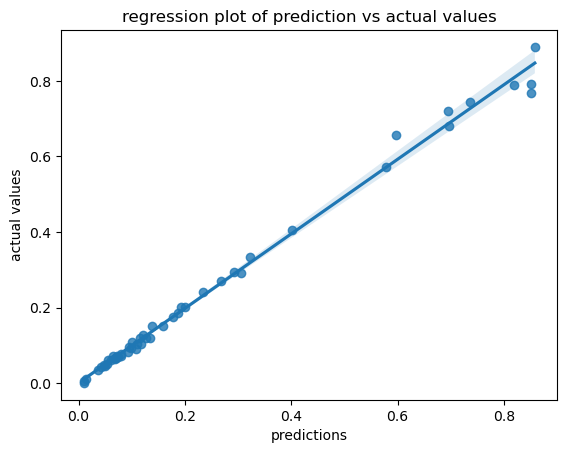

In [90]:
#plotting the regression line fot the result
sns.regplot(x=y_pred,y=y_test)
plt.xlabel('predictions')
plt.ylabel('actual values')
plt.title('regression plot of prediction vs actual values')
plt.show()